# 05 — Visualization

Trực quan hóa mạng sản phẩm và các kết quả nghiên cứu để trình bày quan hệ sản phẩm cùng cơ hội bán chéo.


## 1. Objective & Saved Outputs

Tạo bảy research figures cho RQ1–RQ3 từ kết quả Phase 2–4, dùng cấu hình chính thức Top 100 / Threshold 125. Không đọc transactions, tính lại association, community hay centrality. Các bảng cạnh figure cung cấp số liệu cập nhật từ saved outputs.

Business Review được đọc tại `outputs/tables/cross_selling_business_review.csv`, tự nhận delimiter và đối chiếu bằng directed keys. Nếu thiếu file, sai schema hoặc không đồng bộ thì dừng trước khi vẽ; không sửa input.

GraphML Phase 2 chỉ lưu sản phẩm và cạnh, chưa có community assignments. Màu lấy từ node_metrics và đối chiếu thành viên trong community_summary; nếu GraphML có community_id thì kiểm tra thêm. network_summary.json cung cấp metadata Phase 2 và bối cảnh large invoices.

In [1]:
from pathlib import Path
from io import BytesIO
import sys
import csv
import json
import textwrap
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display
from PIL import Image

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from config import NETWORKS_DIR, TABLES_DIR, FIGURES_DIR, TOP_N_PRODUCTS, MIN_EDGE_WEIGHT, RANDOM_STATE

assert (TOP_N_PRODUCTS, MIN_EDGE_WEIGHT) == (100, 125), "Phase 5 requires the official Top 100/125 configuration."
paths = {
    "graph": NETWORKS_DIR / "product_network.graphml",
    "phase2": NETWORKS_DIR / "network_summary.json",
    "products": TABLES_DIR / "selected_products.csv",
    "nodes": TABLES_DIR / "node_metrics.csv",
    "communities": TABLES_DIR / "community_summary.csv",
    "stability": TABLES_DIR / "community_stability.csv",
    "comparison": TABLES_DIR / "candidate_network_comparison.csv",
    "candidates": TABLES_DIR / "cross_selling_candidates.csv",
    "shortlist": TABLES_DIR / "cross_selling_shortlist.csv",
    "review": TABLES_DIR / "cross_selling_business_review.csv",
}
assert all(p.is_file() for p in paths.values()), f"Missing saved inputs: {[str(p) for p in paths.values() if not p.is_file()]}"
G = nx.read_graphml(paths["graph"])
phase2 = json.loads(paths["phase2"].read_text())
products = pd.read_csv(paths["products"], dtype={"StockCode": "string"})
nodes = pd.read_csv(paths["nodes"], dtype={"StockCode": "string"})
communities = pd.read_csv(paths["communities"])
stability = pd.read_csv(paths["stability"])
comparison = pd.read_csv(paths["comparison"])
rule_keys = ["antecedent", "consequent"]
rule_dtypes = {key: "string" for key in rule_keys}
candidates = pd.read_csv(paths["candidates"], dtype=rule_dtypes)
shortlist = pd.read_csv(paths["shortlist"], dtype=rule_dtypes)
review_delimiter = csv.Sniffer().sniff(paths["review"].read_text()[:8192], delimiters=",;\t").delimiter
review = pd.read_csv(paths["review"], sep=review_delimiter, dtype=rule_dtypes)

In [2]:
required_node_columns = {"StockCode", "Description", "community_id", "strength", "betweenness", "top_n", "threshold", "random_state"}
assert required_node_columns.issubset(nodes), "node_metrics.csv has an invalid schema."
assert {"community_id", "size", "products", "internal_edge_weight", "external_edge_weight"}.issubset(communities), "Invalid community summary schema."
assert nodes["StockCode"].is_unique and products["StockCode"].is_unique
assert set(G) == set(nodes["StockCode"]) == set(products["StockCode"])
assert len(G) == TOP_N_PRODUCTS and not G.is_directed() and not G.is_multigraph()
for frame in [nodes, communities]:
    assert frame[["top_n", "threshold", "random_state"]].eq([TOP_N_PRODUCTS, MIN_EDGE_WEIGHT, RANDOM_STATE]).all().all(), "Phase 3 metadata differs from config."
assert phase2["configuration"] == {"TOP_N_PRODUCTS": TOP_N_PRODUCTS, "MIN_EDGE_WEIGHT": MIN_EDGE_WEIGHT, "RANDOM_STATE": RANDOM_STATE}
assert G.number_of_edges() == phase2["final_graph_metrics"]["edges"]
assert all(float(d["weight"]) >= MIN_EDGE_WEIGHT for _, _, d in G.edges(data=True))
node_info = nodes.set_index("StockCode").sort_index()
assert nodes[["community_id", "strength", "betweenness"]].notna().all().all()
assert np.isfinite(nodes[["strength", "betweenness"]]).all().all()
assert communities["community_id"].is_unique
pd.testing.assert_series_equal(node_info.groupby("community_id").size().sort_index(), communities.set_index("community_id")["size"].sort_index(), check_names=False)
for row in communities.itertuples(index=False):
    members = {p["StockCode"] for p in json.loads(row.products)}
    assert members == set(nodes.loc[nodes["community_id"].eq(row.community_id), "StockCode"]), "Community membership mismatch."
for stock_code, attributes in G.nodes(data=True):
    if "community_id" in attributes:
        assert int(attributes["community_id"]) == node_info.at[stock_code, "community_id"]
    assert attributes["Description"] == node_info.at[stock_code, "Description"]
pd.testing.assert_series_equal(node_info["Description"], products.set_index("StockCode")["Description"].sort_index(), check_names=False)
official_rows = comparison.loc[comparison["graph_role"].eq("official_baseline")]
assert len(official_rows) == 1, "Missing or ambiguous official Phase 3 baseline."
official = official_rows.iloc[0]
assert (official["top_n"], official["threshold"], official["random_state"], official["nodes"], official["edges"]) == (TOP_N_PRODUCTS, MIN_EDGE_WEIGHT, RANDOM_STATE, len(G), G.number_of_edges())
seed_results = stability.loc[stability["config_name"].eq(official["config_name"])].copy()
assert not seed_results.empty and seed_results[["top_n", "threshold", "random_state"]].eq([TOP_N_PRODUCTS, MIN_EDGE_WEIGHT, RANDOM_STATE]).all().all()

association_columns = ["pair_count", "pair_support", "confidence", "lift"]
review_columns = set(rule_keys + association_columns + ["relationship_type", "business_relevance", "review_reason", "review_status", "large_invoice_pair_share", "antecedent_community", "consequent_community", "same_community"])
assert review_columns.issubset(review), f"Business Review missing columns: {sorted(review_columns - set(review))}"
for frame in [candidates, shortlist, review]:
    assert set(rule_keys + association_columns).issubset(frame), "Invalid association table schema."
    assert frame[rule_keys].notna().all().all() and not frame.duplicated(rule_keys).any(), "Missing or duplicate directed rule keys."
    assert set(frame["antecedent"]) | set(frame["consequent"]) <= set(G), "Rule references unselected products."
review_values = review[association_columns + ["large_invoice_pair_share"]].apply(pd.to_numeric, errors="coerce")
assert review_values.notna().all().all() and np.isfinite(review_values).all().all(), "Business Review contains invalid numeric metrics."
assert review_values["large_invoice_pair_share"].between(0, 1).all(), "Business Review large_invoice_pair_share must lie in [0,1]; check decimal parsing in the source CSV."
shortlist_index = pd.MultiIndex.from_frame(shortlist[rule_keys])
pool_rows = candidates.set_index(rule_keys)
assert shortlist_index.isin(pool_rows.index).all(), "Shortlist contains rules outside the candidate pool."
assert np.allclose(shortlist[association_columns], pool_rows.loc[shortlist_index, association_columns], rtol=1e-12, atol=1e-12), "Shortlist metrics differ from candidate pool."
review_rows = review.set_index(rule_keys)
assert len(review) == len(shortlist) and shortlist_index.isin(review_rows.index).all(), "Business Review does not match the current shortlist."
assert np.allclose(shortlist[association_columns + ["large_invoice_pair_share"]], review_rows.loc[shortlist_index, association_columns + ["large_invoice_pair_share"]], rtol=1e-12, atol=1e-12), "Business Review metrics differ from the shortlist."
for column in ["antecedent_community", "consequent_community", "same_community"]:
    assert np.array_equal(shortlist[column], review_rows.loc[shortlist_index, column]), f"Business Review mismatch: {column}"
for frame in [candidates, shortlist]:
    assert np.array_equal(frame["antecedent_community"], frame["antecedent"].map(node_info["community_id"]))
    assert np.array_equal(frame["consequent_community"], frame["consequent"].map(node_info["community_id"]))
assert review["relationship_type"].isin(["same-product-family", "potential-complementary", "potential-substitute", "unclear"]).all()
assert review[["relationship_type", "business_relevance", "review_reason"]].notna().all().all() and review["review_status"].eq("Reviewed").all(), "Business Review is incomplete."
reviewed_shortlist = shortlist.drop(columns="relationship_type").merge(
    review[rule_keys + ["relationship_type", "business_relevance", "review_reason", "review_status"]],
    on=rule_keys, how="left", validate="one_to_one")
display(pd.Series({"nodes": len(G), "edges": G.number_of_edges(), "communities": len(communities),
    "directed_candidates": len(candidates), "shortlisted_rules": len(shortlist),
    "review_delimiter": repr(review_delimiter), "input_validation": "passed"}, name="Saved output checks"))

nodes                     100
edges                    2074
communities                 5
directed_candidates      9794
shortlisted_rules          20
review_delimiter          ';'
input_validation       passed
Name: Saved output checks, dtype: object

## 2. Visualization Setup & Shared Styles

Màu colorblind dùng nhất quán theo Community ID. Figure 1 và 5 dùng chung tọa độ: bắt đầu bằng spring layout trên graph đầy đủ với RANDOM_STATE, rồi đẩy các node chồng lấn ra xa nhau. Hai mức clearance khai báo trong cell setup dành khoảng trống lớn hơn quanh Top 5 Strength hoặc Top 5 Betweenness; dùng lại đúng các bảng xếp hạng đã lưu. Việc tách node chỉ thay đổi tọa độ trình bày, không tạo khoảng cách sản phẩm có ý nghĩa phân tích. Chỉ hiển thị cạnh có weight từ P90 trở lên, giữ mọi cạnh bằng ngưỡng; Figure 5 tiếp tục chỉ giữ cạnh chạm các node được highlight. Đây là lọc để vẽ, không thay đổi graph hoặc kết quả phân tích.

Nhãn sản phẩm rút ngắn và luôn kèm StockCode. Figures dành cho một cột (community sizes) hoặc hai cột IEEE (các hình còn lại), với font khoảng 8–10 pt ở kích thước xuất gốc. Mỗi hình lưu PNG 300 DPI.

In [3]:
sns.set_theme(style="white", context="paper", font="DejaVu Sans", rc={
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
})
community_ids = sorted(communities["community_id"])
community_colors = dict(zip(community_ids, sns.color_palette("colorblind", len(community_ids))))
community_handles = [Line2D([], [], marker="o", linestyle="", color=community_colors[c], label=f"C{c}", markersize=6) for c in community_ids]
top_strength = nodes.sort_values(["strength", "StockCode"], ascending=[False, True]).head(10)
top_betweenness = nodes.sort_values(["betweenness", "StockCode"], ascending=[False, True]).head(10)
strength_highlights = set(top_strength.head(5)["StockCode"])
betweenness_highlights = set(top_betweenness.head(5)["StockCode"])
highlighted = strength_highlights | betweenness_highlights
positions = nx.spring_layout(G, seed=RANDOM_STATE, weight="weight", iterations=200)
edge_cutoff = pd.Series([d["weight"] for _, _, d in G.edges(data=True)]).quantile(0.90)
shown_edges = [(a, b) for a, b, d in G.edges(data=True) if d["weight"] >= edge_cutoff]
node_order = sorted(G)
node_sizes = 20 + 110 * node_info.loc[node_order, "strength"] / node_info["strength"].max()
max_edge_weight = max(d["weight"] for _, _, d in G.edges(data=True))
# Separate overlapping nodes in layout coordinates; reserve more space for central products.
NODE_CLEARANCE = 0.055
CENTRAL_NODE_CLEARANCE = 0.125
position_array = np.array([positions[p] for p in node_order])
clearance = np.array([CENTRAL_NODE_CLEARANCE if p in highlighted else NODE_CLEARANCE for p in node_order])
minimum_spacing = clearance[:, None] + clearance[None, :]
for _ in range(300):
    offsets = position_array[:, None, :] - position_array[None, :, :]
    distances = np.linalg.norm(offsets, axis=2)
    np.fill_diagonal(distances, np.inf)
    overlaps = np.maximum(minimum_spacing - distances, 0)
    if overlaps.max() < 1e-4:
        break
    position_array += 0.4 * (offsets / np.maximum(distances[:, :, None], 1e-9) * overlaps[:, :, None]).sum(axis=1)
positions = dict(zip(node_order, position_array))
x_min, y_min = position_array.min(axis=0)
x_max, y_max = position_array.max(axis=0)
exported_stems = []

def product_label(stock_code, width=31):
    description = " ".join(node_info.at[stock_code, "Description"].split())
    return textwrap.shorten(description, width=width, placeholder="…") + f"\n[{stock_code}]"

def save_figure(fig, stem):
    image_buffer = BytesIO()
    fig.savefig(image_buffer, format="png", dpi=300, bbox_inches="tight", facecolor="white")
    image_path = FIGURES_DIR / f"{stem}.png"
    image_bytes = image_buffer.getvalue()
    if not image_path.exists() or image_path.read_bytes() != image_bytes:
        image_path.write_bytes(image_bytes)
    exported_stems.append(stem)
    plt.show()
    plt.close(fig)

def draw_network(ax, edges, labels):
    widths = [0.35 + 1.0 * G[a][b]["weight"] / max_edge_weight for a, b in edges]
    nx.draw_networkx_edges(G, positions, ax=ax, edgelist=edges, width=widths, alpha=0.23, edge_color="#66717d")
    nx.draw_networkx_nodes(G, positions, ax=ax, nodelist=node_order, node_size=node_sizes,
        node_color=[community_colors[node_info.at[p, "community_id"]] for p in node_order],
        edgecolors="white", linewidths=0.45)
    for side in [-1, 1]:
        side_labels = sorted([p for p in labels if (positions[p][0] >= 0) == (side == 1)], key=lambda p: positions[p][1])
        label_y = np.linspace(y_min + 0.15, y_max - 0.15, len(side_labels)) if len(side_labels) > 1 else [(y_min + y_max) / 2]
        for stock_code, y in zip(side_labels, label_y):
            ax.annotate(stock_code, xy=positions[stock_code], xytext=(x_min - 0.18 if side == -1 else x_max + 0.18, y),
                ha="left" if side == 1 else "right", va="center", fontsize=8,
                arrowprops={"arrowstyle": "-", "color": "#555555", "lw": 0.6},
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5})
    ax.set(xlim=(x_min - 0.45, x_max + 0.45), ylim=(y_min - 0.12, y_max + 0.12))
    ax.set_axis_off()

## 3. RQ1 — Community Visualizations

### Figure 1 — Weighted Product Network by Community

**Research Question:** RQ1 — Mạng mua chung có cấu trúc cộng đồng như thế nào?

**Key Finding:** Các cộng đồng khác nhau về quy mô và có cả liên kết giữa nhóm. Bảng dưới ghi số node/cạnh đầy đủ và cạnh thực sự hiển thị.

**Interpretation:** Màu là community đã lưu; diện tích node tăng theo Strength; cạnh dày hơn thể hiện nhiều hóa đơn mua chung hơn. Chỉ gắn nhãn sản phẩm có Strength cao nhất trong mỗi community.

**Limitation:** Vị trí và cạnh bị ẩn chỉ phục vụ trình bày. Khoảng cách trên hình không phải khoảng cách sản phẩm được kiểm định; màu không xác nhận nhóm ngành hàng đồng nhất.

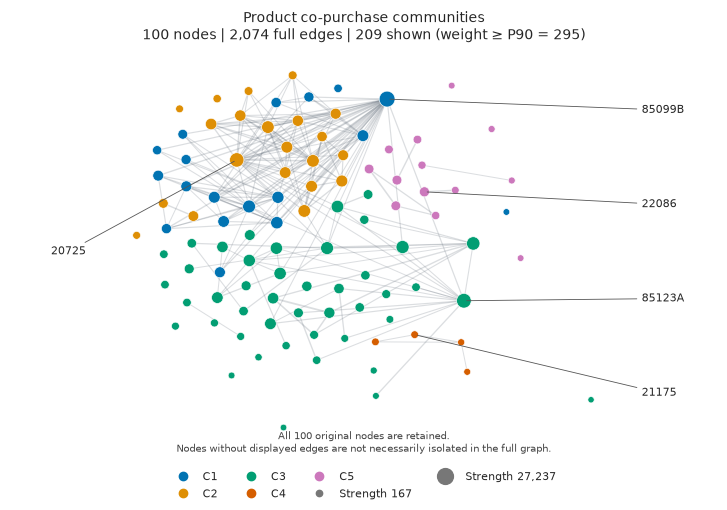

,community_id,StockCode,Description,strength
95,1,85099B,JUMBO BAG RED RETROSPOT,27237
5,2,20725,LUNCH BAG RED RETROSPOT,21481
98,3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,22551
13,4,21175,GIN + TONIC DIET METAL SIGN,2687
27,5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,7941


full_edges                   2074.0
shown_edges                   209.0
display_weight_cutoff_P90     295.0
Name: Figure 1 edge display, dtype: float64

In [4]:
community_representatives = nodes.sort_values(["strength", "StockCode"], ascending=[False, True]).groupby("community_id", sort=True).head(1)
fig, ax = plt.subplots(figsize=(7.16, 5.0), layout="constrained")
draw_network(ax, shown_edges, community_representatives["StockCode"])
ax.set_title(f"Product co-purchase communities\n{len(G)} nodes | {G.number_of_edges():,} full edges | {len(shown_edges):,} shown (weight ≥ P90 = {edge_cutoff:g})")
ax.text(0.5, 0.0, f"All {len(G)} original nodes are retained.\nNodes without displayed edges are not necessarily isolated in the full graph.",
    transform=ax.transAxes, ha="center", va="bottom", fontsize=7.5, color="#444444")
size_examples = [node_info["strength"].min(), node_info["strength"].max()]
size_handles = [Line2D([], [], marker="o", linestyle="", color="#777777", markersize=np.sqrt(20 + 110 * s / node_info["strength"].max()), label=f"Strength {s:,.0f}") for s in size_examples]
fig.legend(handles=community_handles + size_handles, loc="outside lower center", ncol=4, frameon=False)
save_figure(fig, "rq1_community_network")
display(community_representatives[["community_id", "StockCode", "Description", "strength"]].sort_values("community_id"))
display(pd.Series({"full_edges": G.number_of_edges(), "shown_edges": len(shown_edges), "display_weight_cutoff_P90": edge_cutoff}, name="Figure 1 edge display"))

### Figure 2 — Community Size & Statistics

**Research Question:** RQ1 — Số sản phẩm phân bố giữa các community ra sao?

**Key Finding:** Kích thước các nhóm không đồng đều; bảng sắp theo size xác định nhóm lớn/nhỏ nhất ở lần chạy hiện tại.

**Interpretation:** Size mô tả quy mô phân hoạch. Bảng internal/external weights bổ sung bối cảnh về mức liên kết nhưng không dùng để gán nhãn kinh doanh.

**Limitation:** Nhóm lớn có thể chứa nhiều nhóm sản phẩm khác nhau; số thành viên lớn không bảo đảm chất lượng hay tính đồng nhất cao hơn. External weight của một cạnh được tính ở cả hai community liên quan.

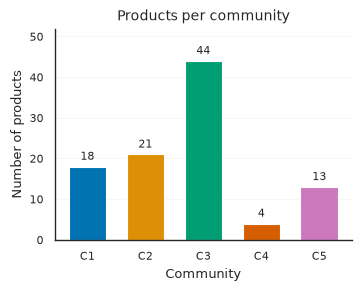

,community_id,size,internal_edge_weight,external_edge_weight
2,3,44,100940,136709
1,2,21,49311,120997
0,1,18,40042,112046
4,5,13,7726,37280
3,4,4,1768,4486


In [5]:
community_plot = communities.sort_values("community_id")
fig, ax = plt.subplots(figsize=(3.5, 2.8), layout="constrained")
bars = ax.bar([f"C{c}" for c in community_plot["community_id"]], community_plot["size"], color=[community_colors[c] for c in community_plot["community_id"]], width=0.65)
ax.bar_label(bars, padding=3, fontsize=8)
ax.set(title="Products per community", xlabel="Community", ylabel="Number of products", ylim=(0, community_plot["size"].max() * 1.18))
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)
save_figure(fig, "rq1_community_sizes")
display(communities[["community_id", "size", "internal_edge_weight", "external_edge_weight"]].sort_values("size", ascending=False))

### Community Interpretation Table — RQ1

Chọn 3 sản phẩm đại diện mỗi community theo Strength giảm dần, ties theo StockCode. Size và edge weights lấy nguyên từ community_summary; tên và Strength lấy từ node_metrics.

Dominant Product Pattern là nhận xét định tính sau khi đọc toàn bộ Description của từng nhóm trong output hiện tại; C3/C5 được ghi rõ là mixed/diverse. Các nhận xét này cần review lại nếu assignments Phase 3 thay đổi.

In [6]:
community_patterns = {
    1: "Mainly Jumbo/storage bags; also a doormat.",
    2: "Mainly lunch/Charlotte bags and lunch boxes; also plasters in a tin.",
    3: "Mixed/diverse tableware, baking items and home decorations.",
    4: "Text-based signs, mainly labelled METAL SIGN.",
    5: "Mixed/diverse clocks, hot-water bottles, kneeling pads and home/seasonal items.",
}
community_rows = []
for community in communities.sort_values("community_id").itertuples(index=False):
    representatives = nodes.loc[nodes["community_id"].eq(community.community_id)].sort_values(
        ["strength", "StockCode"], ascending=[False, True]).head(3)
    community_rows.append({
        "Community": f"C{community.community_id}", "Size": community.size,
        "Representative Products": "; ".join(f"{description} [{code}]" for code, description in representatives[["StockCode", "Description"]].itertuples(index=False, name=None)),
        "Dominant Product Pattern": community_patterns[community.community_id],
        "Internal Edge Weight": community.internal_edge_weight,
        "External Edge Weight": community.external_edge_weight,
    })
community_interpretation = pd.DataFrame(community_rows)
with pd.option_context("display.max_colwidth", None):
    display(community_interpretation)

,Community,Size,Representative Products,Dominant Product Pattern,Internal Edge Weight,External Edge Weight
0,C1,18,JUMBO BAG RED RETROSPOT [85099B]; JUMBO STORAGE BAG SUKI [21931]; JUMBO SHOPPER VINTAGE RED PAISLEY [22411],Mainly Jumbo/storage bags; also a doormat.,40042,112046
1,C2,21,LUNCH BAG RED RETROSPOT [20725]; LUNCH BAG BLACK SKULL. [20727]; LUNCH BAG SUKI DESIGN [22383],Mainly lunch/Charlotte bags and lunch boxes; also plasters in a tin.,49311,120997
2,C3,44,WHITE HANGING HEART T-LIGHT HOLDER [85123A]; REGENCY CAKESTAND 3 TIER [22423]; POPCORN HOLDER [22197],"Mixed/diverse tableware, baking items and home decorations.",100940,136709
3,C4,4,GIN + TONIC DIET METAL SIGN [21175]; PLEASE ONE PERSON METAL SIGN [21181]; COOK WITH WINE METAL SIGN [21166],"Text-based signs, mainly labelled METAL SIGN.",1768,4486
4,C5,13,PAPER CHAIN KIT 50'S CHRISTMAS [22086]; GARDENERS KNEELING PAD KEEP CALM [23301]; ALARM CLOCK BAKELIKE GREEN [22726],"Mixed/diverse clocks, hot-water bottles, kneeling pads and home/seasonal items.",7726,37280


## 4. RQ2 — Centrality Visualizations

### Figure 3 — Top 10 Products by Strength

**Research Question:** RQ2 — Sản phẩm nào tích lũy nhiều liên kết mua chung nhất?

**Key Finding:** Strength tập trung mạnh ở các sản phẩm đầu bảng; tên, StockCode và giá trị cụ thể được đọc trực tiếp từ bảng top 10.

**Interpretation:** Strength là tổng co-purchase weights trên các cạnh được giữ trong graph chính thức. Nó thể hiện tổng tần suất liên kết, không phải số hóa đơn riêng biệt của sản phẩm.

**Limitation:** Một hóa đơn có thể đóng góp vào nhiều cạnh. Strength không đo doanh thu, lợi nhuận hoặc tác động nhân quả; màu chỉ thể hiện community.

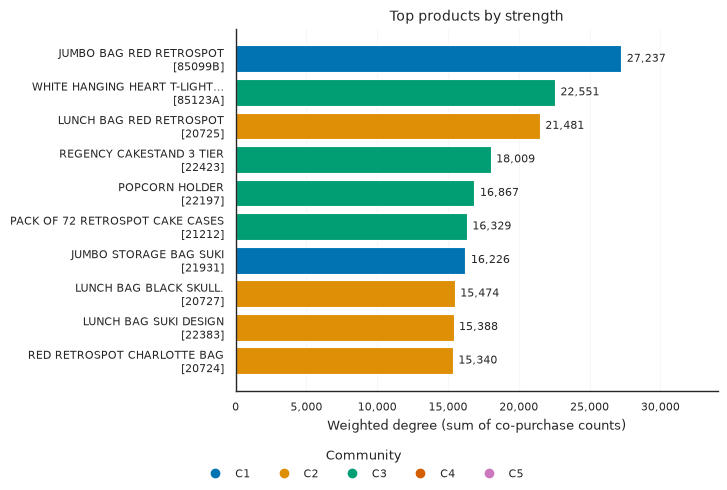

,StockCode,Description,community_id,strength
95,85099B,JUMBO BAG RED RETROSPOT,1,27237
98,85123A,WHITE HANGING HEART T-LIGHT HOLDER,3,22551
5,20725,LUNCH BAG RED RETROSPOT,2,21481
45,22423,REGENCY CAKESTAND 3 TIER,3,18009
34,22197,POPCORN HOLDER,3,16867
15,21212,PACK OF 72 RETROSPOT CAKE CASES,3,16329
24,21931,JUMBO STORAGE BAG SUKI,1,16226
7,20727,LUNCH BAG BLACK SKULL.,2,15474
40,22383,LUNCH BAG SUKI DESIGN,2,15388
4,20724,RED RETROSPOT CHARLOTTE BAG,2,15340


In [7]:
fig, ax = plt.subplots(figsize=(7.16, 4.8), layout="constrained")
bars = ax.barh(range(len(top_strength)), top_strength["strength"], color=[community_colors[c] for c in top_strength["community_id"]])
ax.set_yticks(range(len(top_strength)), [product_label(p) for p in top_strength["StockCode"]])
ax.invert_yaxis()
ax.bar_label(bars, fmt="{:,.0f}", padding=4, fontsize=8)
ax.set(title="Top products by strength", xlabel="Weighted degree (sum of co-purchase counts)", xlim=(0, top_strength["strength"].max() * 1.25))
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
fig.legend(handles=community_handles, loc="outside lower center", ncol=len(community_ids), frameon=False, title="Community")
save_figure(fig, "rq2_top_strength")
display(top_strength[["StockCode", "Description", "community_id", "strength"]])

### Figure 4 — Top 10 Products by Betweenness Centrality

**Research Question:** RQ2 — Sản phẩm nào nằm trên nhiều đường đi ngắn nhất có trọng số?

**Key Finding:** Betweenness phân bố tập trung và nhiều sản phẩm có giá trị bằng 0; bảng kèm theo cập nhật số lượng này. Thứ hạng không hoàn toàn trùng Strength.

**Interpretation:** Dùng đúng betweenness đã lưu ở Phase 3, với distance = 1 / weight và giá trị normalized. Cạnh mua chung thường xuyên hơn có distance nhỏ hơn trong mô hình này.

**Limitation:** Không tính lại shortest paths. Giá trị 0 không có nghĩa sản phẩm không được mua chung; betweenness cao chưa chứng minh sản phẩm là trung gian trong hành vi khách hàng.

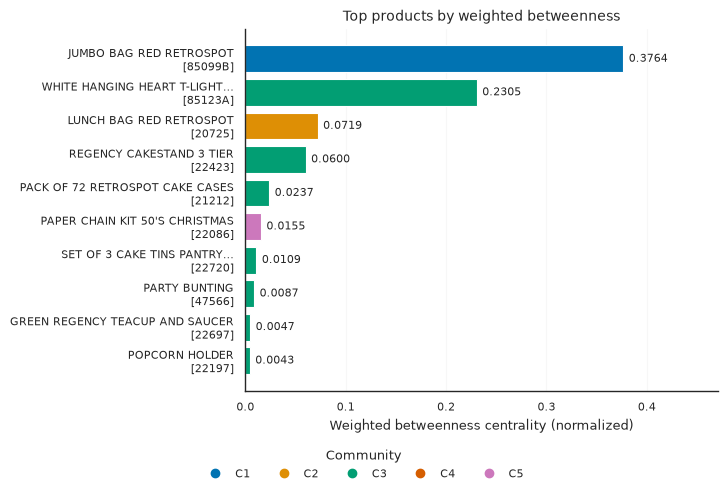

,StockCode,Description,community_id,betweenness
95,85099B,JUMBO BAG RED RETROSPOT,1,0.376417
98,85123A,WHITE HANGING HEART T-LIGHT HOLDER,3,0.230468
5,20725,LUNCH BAG RED RETROSPOT,2,0.071944
45,22423,REGENCY CAKESTAND 3 TIER,3,0.059988
15,21212,PACK OF 72 RETROSPOT CAKE CASES,3,0.023706
27,22086,PAPER CHAIN KIT 50'S CHRISTMAS,5,0.015461
61,22720,SET OF 3 CAKE TINS PANTRY DESIGN,3,0.010926
85,47566,PARTY BUNTING,3,0.008658
58,22697,GREEN REGENCY TEACUP AND SAUCER,3,0.004741
34,22197,POPCORN HOLDER,3,0.004329


zero_betweenness_products     71
total_products               100
Name: Zero betweenness context, dtype: int64

In [8]:
fig, ax = plt.subplots(figsize=(7.16, 4.8), layout="constrained")
bars = ax.barh(range(len(top_betweenness)), top_betweenness["betweenness"], color=[community_colors[c] for c in top_betweenness["community_id"]])
ax.set_yticks(range(len(top_betweenness)), [product_label(p) for p in top_betweenness["StockCode"]])
ax.invert_yaxis()
ax.bar_label(bars, fmt="{:.4f}", padding=4, fontsize=8)
ax.set(title="Top products by weighted betweenness", xlabel="Weighted betweenness centrality (normalized)", xlim=(0, top_betweenness["betweenness"].max() * 1.25))
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
fig.legend(handles=community_handles, loc="outside lower center", ncol=len(community_ids), frameon=False, title="Community")
save_figure(fig, "rq2_top_betweenness")
display(top_betweenness[["StockCode", "Description", "community_id", "betweenness"]])
display(pd.Series({"zero_betweenness_products": int(nodes["betweenness"].eq(0).sum()), "total_products": len(nodes)}, name="Zero betweenness context"))

### Figure 5 — Central Products in the Network

**Research Question:** RQ2 — Các sản phẩm quan trọng theo hai centralities nằm ở đâu trong mạng?

**Key Finding:** Top sản phẩm theo Strength và Betweenness có phần giao nhau và phần khác nhau; bảng dưới xác định vai trò của từng node được highlight.

**Interpretation:** Chọn top 5 cho mỗi chỉ số (ties theo StockCode), dùng viền vuông cho Strength-only, hình thoi cho Betweenness-only và tròn cho cả hai. Màu và node positions giữ nguyên Figure 1; khoảng trống lớn hơn quanh các node highlight giúp phân biệt các vai trò. Nhãn tên rút gọn kèm StockCode đặt gần node, với đường dẫn ngắn.

**Limitation:** Chỉ hiển thị các cạnh mạnh của Figure 1 chạm node highlight. Vai trò và centralities vẫn thuộc graph đầy đủ; không suy ra centrality từ riêng hình đã lọc.

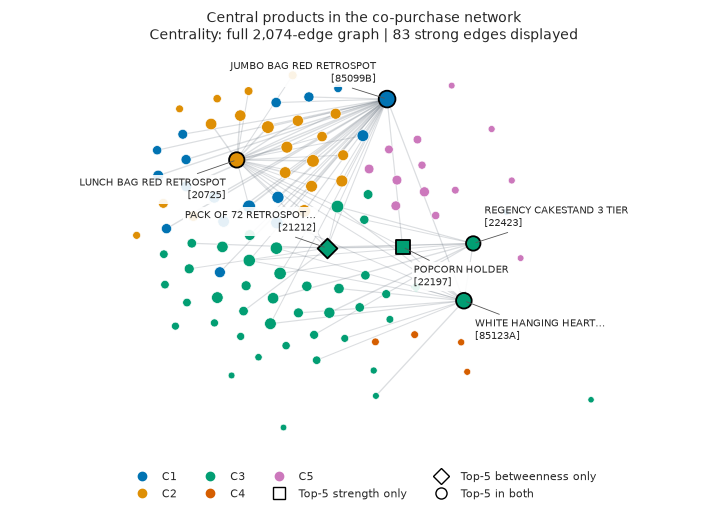

,Description,community_id,strength,betweenness,highlight_role
StockCode,,,,,
20725,LUNCH BAG RED RETROSPOT,2,21481,0.071944,both
21212,PACK OF 72 RETROSPOT CAKE CASES,3,16329,0.023706,betweenness only
22197,POPCORN HOLDER,3,16867,0.004329,strength only
22423,REGENCY CAKESTAND 3 TIER,3,18009,0.059988,both
85099B,JUMBO BAG RED RETROSPOT,1,27237,0.376417,both
85123A,WHITE HANGING HEART T-LIGHT HOLDER,3,22551,0.230468,both


In [9]:
central_edges = [(a, b) for a, b in shown_edges if a in highlighted or b in highlighted]
roles = [
    ("Top-5 strength only", strength_highlights - betweenness_highlights, "s"),
    ("Top-5 betweenness only", betweenness_highlights - strength_highlights, "D"),
    ("Top-5 in both", strength_highlights & betweenness_highlights, "o"),
]
fig, ax = plt.subplots(figsize=(7.16, 5.0), layout="constrained")
draw_network(ax, central_edges, [])
role_handles = []
for label, codes, marker in roles:
    codes = sorted(codes)
    if codes:
        ax.scatter([positions[p][0] for p in codes], [positions[p][1] for p in codes],
            s=[node_sizes.loc[p] + 15 for p in codes], marker=marker, c=[community_colors[node_info.at[p, "community_id"]] for p in codes], edgecolors="black", linewidths=1.3, zorder=4)
        role_handles.append(Line2D([], [], marker=marker, linestyle="", markerfacecolor="none", markeredgecolor="black", label=label, markersize=8))
label_midpoint = np.median([positions[p][0] for p in highlighted])
for index, stock_code in enumerate(sorted(highlighted, key=lambda p: (-positions[p][1], p))):
    dx = 8 if positions[stock_code][0] >= label_midpoint else -8
    dy = 10 if index % 2 == 0 else -12
    ax.annotate(product_label(stock_code, 25), xy=positions[stock_code], xytext=(dx, dy), textcoords="offset points",
        ha="left" if dx > 0 else "right", va="bottom" if dy > 0 else "top", fontsize=7.5,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9, "pad": 1.5},
        arrowprops={"arrowstyle": "-", "color": "#555555", "lw": 0.6}, zorder=5)
ax.set_title(f"Central products in the co-purchase network\nCentrality: full {G.number_of_edges():,}-edge graph | {len(central_edges):,} strong edges displayed")
fig.legend(handles=community_handles + role_handles, loc="outside lower center", ncol=4, frameon=False)
save_figure(fig, "rq2_central_products_network")
central_table = node_info.loc[sorted(highlighted), ["Description", "community_id", "strength", "betweenness"]].copy()
central_table["highlight_role"] = ["both" if p in strength_highlights & betweenness_highlights else "strength only" if p in strength_highlights else "betweenness only" for p in central_table.index]
display(central_table)

## 5. RQ3 — Association & Cross-selling Visualizations

### Figure 6 — Product Association Heatmap

**Research Question:** RQ3 — Những sản phẩm có association nổi bật liên kết với nhau ra sao?

**Key Finding:** Mức mua chung không đồng đều giữa các cặp; các ô đậm cho biết cặp phổ biến hơn trong tập sản phẩm được chọn. Bảng bên dưới ghi rõ sản phẩm, community và tiêu chí chọn.

**Interpretation:** Chọn tối đa 3 sản phẩm mỗi community từ các endpoints của shortlist, ưu tiên max Pair Support trong các rules đã được chọn, rồi max Lift và StockCode. Trục X dùng StockCode, trục Y dùng tên rút gọn kèm StockCode, cùng thứ tự sản phẩm. Sắp theo community để dễ đọc; màu ô chỉ biểu diễn Pair Support (%), không phải community hoặc Confidence.

**Limitation:** Đây là tập con để trình bày, không đại diện toàn bộ danh mục. Support đối xứng nên hai hướng dùng cùng giá trị. Ô xám là đường chéo hoặc cặp không có trong candidate pool (có thể không đạt MIN_RULE_PAIR_COUNT/Lift > 1), không được coi là 0. Không dùng graph threshold 125 để lọc association.

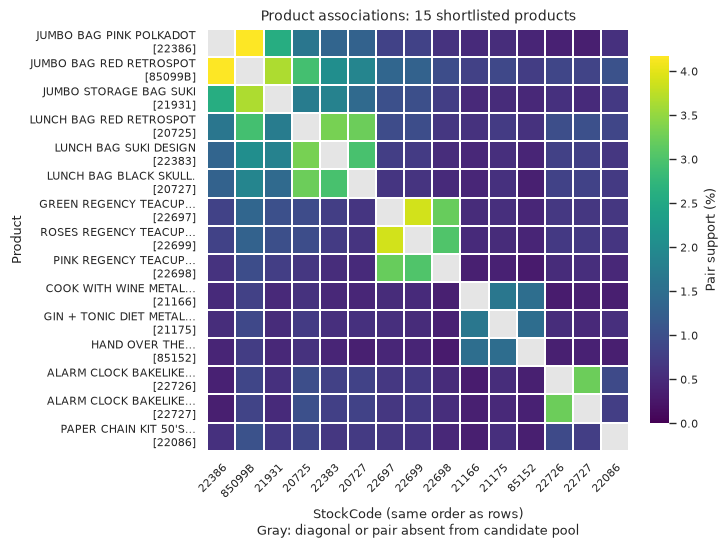

,StockCode,Description,community_id,max_pair_support,max_lift
9,22386,JUMBO BAG PINK POLKADOT,1,0.041724,6.411222
27,85099B,JUMBO BAG RED RETROSPOT,1,0.041724,6.411222
5,21931,JUMBO STORAGE BAG SUKI,1,0.036616,7.447565
1,20725,LUNCH BAG RED RETROSPOT,2,0.033126,6.445172
8,22383,LUNCH BAG SUKI DESIGN,2,0.033126,6.445172
2,20727,LUNCH BAG BLACK SKULL.,2,0.032418,6.361915
13,22697,GREEN REGENCY TEACUP AND SAUCER,3,0.038790,16.125707
15,22699,ROSES REGENCY TEACUP AND SAUCER,3,0.038790,14.513184
14,22698,PINK REGENCY TEACUP AND SAUCER,3,0.031963,16.125707
3,21166,COOK WITH WINE METAL SIGN,4,0.016588,11.917019


In [10]:
canonical = np.sort(candidates[rule_keys].to_numpy(), axis=1)
plot_pairs = candidates.assign(product_a=canonical[:, 0], product_b=canonical[:, 1])
assert plot_pairs.groupby(["product_a", "product_b"])[["pair_support", "lift"]].nunique().le(1).all().all(), "Symmetric association metrics differ between directions."
plot_pairs = plot_pairs.drop_duplicates(["product_a", "product_b"]).copy()
endpoint_metrics = pd.concat([
    shortlist[["antecedent", "pair_support", "lift"]].rename(columns={"antecedent": "StockCode"}),
    shortlist[["consequent", "pair_support", "lift"]].rename(columns={"consequent": "StockCode"}),
], ignore_index=True).groupby("StockCode").agg(max_pair_support=("pair_support", "max"), max_lift=("lift", "max"))
heat_products = node_info.join(endpoint_metrics).dropna(subset="max_pair_support").reset_index().sort_values(
    ["max_pair_support", "max_lift", "StockCode"], ascending=[False, False, True]).groupby("community_id").head(3)
heat_products = heat_products.sort_values(["community_id", "max_pair_support", "StockCode"], ascending=[True, False, True])
heat_codes = heat_products["StockCode"].tolist()
assert 12 <= len(heat_codes) <= 20, "The current shortlist does not supply 12–20 products under the stated heatmap selection rule."
heat_pairs = plot_pairs.loc[plot_pairs["product_a"].isin(heat_codes) & plot_pairs["product_b"].isin(heat_codes), ["product_a", "product_b", "pair_support"]]
heat_long = pd.concat([heat_pairs.rename(columns={"product_a": "row", "product_b": "column"}), heat_pairs.rename(columns={"product_b": "row", "product_a": "column"})])
heat_matrix = heat_long.pivot(index="row", columns="column", values="pair_support").reindex(index=heat_codes, columns=heat_codes) * 100
assert np.isnan(np.diag(heat_matrix)).all() and np.allclose(heat_matrix, heat_matrix.T, equal_nan=True)
fig, ax = plt.subplots(figsize=(7.16, 6.2), layout="constrained")
ax.set_facecolor("#e5e5e5")
sns.heatmap(heat_matrix, mask=heat_matrix.isna(), cmap="viridis", vmin=0, square=True,
    linewidths=0.35, linecolor="white", cbar_kws={"label": "Pair support (%)", "shrink": 0.65}, ax=ax,
    xticklabels=heat_codes, yticklabels=[product_label(p, 23) for p in heat_codes])
ax.tick_params(axis="both", labelsize=8)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
plt.setp(ax.get_yticklabels(), rotation=0)
ax.set(title=f"Product associations: {len(heat_codes)} shortlisted products", ylabel="Product", xlabel="StockCode (same order as rows)\nGray: diagonal or pair absent from candidate pool")
save_figure(fig, "rq3_association_heatmap")
display(heat_products[["StockCode", "Description", "community_id", "max_pair_support", "max_lift"]])

### Figure 7 — Support vs Lift

**Research Question:** RQ3 — Shortlist có vị trí như thế nào trong toàn bộ association pool?

**Key Finding:** Business Review xác định phần lớn shortlisted rules thuộc same-product-family; bảng đếm bên dưới đối chiếu với same/cross-community và business relevance.

**Interpretation:** Nền xám biểu diễn mỗi unordered candidate pair một lần. Các điểm nổi bật là shortlist, dùng màu/ký hiệu theo relationship_type từ Business Review đã hoàn thành. Viền tròn đen đánh dấu large_invoice_caution đã lưu; không loại hoặc xếp lại rules.

**Limitation:** Hai hướng có Support và Lift giống nhau nên vị trí không thể hiện Confidence hoặc hướng gợi ý. Pareto selection dùng metrics; Business Review bổ sung đánh giá sau lựa chọn. Các cặp cùng dòng có thể phù hợp để thử multi-variant promotion, nhưng chưa chứng minh complementary cross-selling; nhãn potential cũng vẫn là giả thuyết.

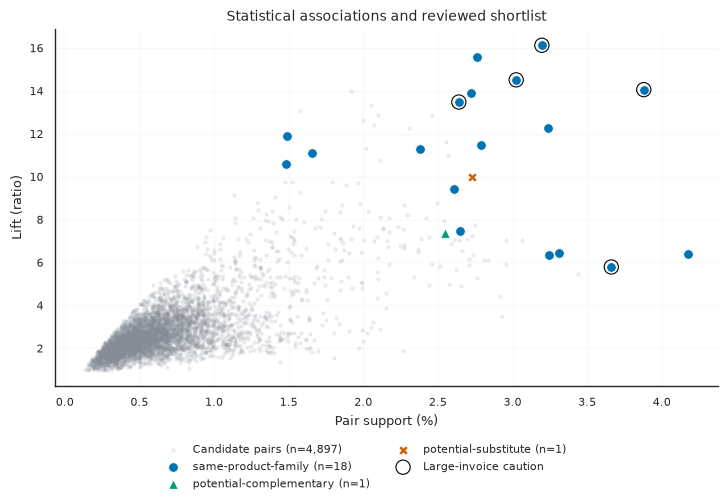

business_relevance,Low,Medium
relationship_type,,
potential-complementary,0,1
potential-substitute,1,0
same-product-family,0,18


,shortlisted_rules,share
same_community,,
False,1,0.05
True,19,0.95


,shortlist_rank,antecedent,consequent,relationship_type,business_relevance,review_reason,large_invoice_pair_share
0,1,22386,85099B,same-product-family,Medium,Both are Jumbo storage bags with different pol...,0.181818
1,2,22697,22699,same-product-family,Medium,Both are Regency teacup-and-saucer sets with d...,0.282920
2,3,22698,22697,same-product-family,Medium,Both are Regency teacup-and-saucer sets in dif...,0.259494
3,4,22698,22699,same-product-family,Medium,Both are Regency teacup-and-saucer sets with d...,0.262542
4,5,23300,23301,same-product-family,Medium,Both are gardening kneeling pads with differen...,0.238095
5,6,21931,85099B,same-product-family,Medium,Both are large Jumbo storage bags with differe...,0.243094
6,7,22383,20725,same-product-family,Medium,Both are lunch bags with different patterns.,0.178626
7,8,22726,22727,same-product-family,Medium,Both are Bakelike alarm clocks in different co...,0.125000
8,9,22910,22086,same-product-family,Medium,Both are Christmas paper-chain decoration kits...,0.210145
9,10,22630,22629,same-product-family,Medium,Both are lunch boxes with different character ...,0.211896


In [11]:
relationship_styles = {
    "same-product-family": (sns.color_palette("colorblind")[0], "o"),
    "potential-complementary": (sns.color_palette("colorblind")[2], "^"),
    "potential-substitute": (sns.color_palette("colorblind")[3], "X"),
    "unclear": ("#777777", "s"),
}
fig, ax = plt.subplots(figsize=(7.16, 4.9), layout="constrained")
ax.scatter(plot_pairs["pair_support"] * 100, plot_pairs["lift"], s=9, alpha=0.18, color="#858c96", linewidths=0, label=f"Candidate pairs (n={len(plot_pairs):,})")
for relationship, (color, marker) in relationship_styles.items():
    subset = reviewed_shortlist.loc[reviewed_shortlist["relationship_type"].eq(relationship)]
    if not subset.empty:
        ax.scatter(subset["pair_support"] * 100, subset["lift"], s=48, c=[color], marker=marker,
            edgecolors="white", linewidths=0.6, zorder=3, label=f"{relationship} (n={len(subset)})")
caution = reviewed_shortlist.loc[reviewed_shortlist["large_invoice_caution"]]
if not caution.empty:
    ax.scatter(caution["pair_support"] * 100, caution["lift"], s=105, facecolors="none", edgecolors="black", linewidths=0.8, zorder=4, label="Large-invoice caution")
ax.set(title="Statistical associations and reviewed shortlist", xlabel="Pair support (%)", ylabel="Lift (ratio)")
ax.grid(alpha=0.12)
fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
save_figure(fig, "rq3_support_vs_lift")
display(pd.crosstab(reviewed_shortlist["relationship_type"], reviewed_shortlist["business_relevance"]))
display(reviewed_shortlist.groupby("same_community").size().rename("shortlisted_rules").to_frame().assign(share=lambda table: table["shortlisted_rules"] / len(reviewed_shortlist)))
display(reviewed_shortlist[["shortlist_rank"] + rule_keys + ["relationship_type", "business_relevance", "review_reason", "large_invoice_pair_share"]])

### Representative Association Rules Table — RQ3

Dùng lại reviewed_shortlist đã merge bằng antecedent và consequent. Chọn rule có shortlist_rank nhỏ nhất cho mỗi relationship_type hiện có, rồi bổ sung theo shortlist_rank để có tối đa 4 ví dụ; ties theo StockCode. Không chỉ chọn Lift cao nhất.

Tên sản phẩm và mũi tên giữ đúng hướng A → B. Support/Confidence chỉ đổi sang phần trăm để trình bày; metrics và Business Review nguồn giữ nguyên.

In [12]:
ordered_examples = reviewed_shortlist.sort_values(["shortlist_rank", "antecedent", "consequent"])
type_examples = ordered_examples.drop_duplicates("relationship_type")
representative_rules = pd.concat([type_examples, ordered_examples]).drop_duplicates(rule_keys).head(4).sort_values("shortlist_rank").reset_index(drop=True)
representative_rule_table = pd.DataFrame({
    "Association Rule": [f"{a_name} [{a}] → {b_name} [{b}]" for a, b, a_name, b_name in representative_rules[
        ["antecedent", "consequent", "antecedent_description", "consequent_description"]].itertuples(index=False, name=None)],
    "Pair Support (%)": representative_rules["pair_support"] * 100,
    "Confidence (%)": representative_rules["confidence"] * 100,
    "Lift": representative_rules["lift"],
    "Relationship Type": representative_rules["relationship_type"],
    "Business Relevance": representative_rules["business_relevance"],
})
with pd.option_context("display.max_colwidth", None):
    display(representative_rule_table.round(2))

,Association Rule,Pair Support (%),Confidence (%),Lift,Relationship Type,Business Relevance
0,JUMBO BAG PINK POLKADOT [22386] → JUMBO BAG RED RETROSPOT [85099B],4.17,67.73,6.41,same-product-family,Medium
1,GREEN REGENCY TEACUP AND SAUCER [22697] → ROSES REGENCY TEACUP AND SAUCER [22699],3.88,75.72,14.06,same-product-family,Medium
2,WOODEN FRAME ANTIQUE WHITE [82494L] → WOODEN PICTURE FRAME WHITE FINISH [82482],2.73,55.51,9.98,potential-substitute,Low
3,LUNCH BAG VINTAGE DOILY [23209] → JUMBO BAG VINTAGE DOILY [23203],2.55,45.90,7.37,potential-complementary,Medium


## 6. Research Findings & Limitations

**RQ1:** Community sizes và nội dung sản phẩm cần được đọc cùng nhau. Seed stability đã lưu mô tả mức ổn định của Louvain trên cùng graph; không đồng nghĩa ổn định khi thay đổi dữ liệu. Kết quả robustness lưu trong notebook 03 cho thấy phân hoạch nhạy với large invoices. Bảng dưới dùng saved sensitivity Phase 2 để nhắc lại mức đóng góp của chúng, không tính lại ARI hay cộng đồng.

**RQ2:** Strength và weighted Betweenness phản ánh hai khía cạnh của vị trí cấu trúc. Sản phẩm dẫn đầu và mức giao nhau giữa hai top 10 được cập nhật từ bảng đã lưu; không suy ra doanh thu hoặc ảnh hưởng nhân quả.

**RQ3:** Business Review được giữ nguyên nhãn, relevance và lý do. Các cặp same-product-family cần phân biệt nhu cầu mua nhiều biến thể với khả năng thay thế; potential-complementary cần xác minh bối cảnh. Shortlist là tập giả thuyết cho thử nghiệm, không phải phương án tối ưu doanh thu. Large invoices và phạm vi Top N giới hạn khả năng khái quát.

Tất cả số liệu trong các bảng tổng kết lấy từ saved outputs. Layout, lọc cạnh và chọn tập con heatmap chỉ ảnh hưởng cách trình bày.

In [13]:
large_invoice = phase2["sensitivity_analysis"]["large_invoices"]
summary_findings = pd.Series({
    "largest_community": f"C{communities.loc[communities['size'].idxmax(), 'community_id']}",
    "largest_community_products": communities["size"].max(),
    "smallest_community_products": communities["size"].min(),
    "saved_weighted_modularity": official["weighted_modularity"],
    "saved_mean_pairwise_seed_ARI": official["mean_pairwise_ari"],
    "saved_min_pairwise_seed_ARI": official["min_pairwise_ari"],
    "large_invoice_selected_pair_weight_pct": large_invoice["large_invoice_selected_product_event_pct"],
    "strength_leader": top_strength.iloc[0]["Description"],
    "betweenness_leader": top_betweenness.iloc[0]["Description"],
    "top10_centrality_overlap": len(set(top_strength["StockCode"]) & set(top_betweenness["StockCode"])),
    "reviewed_shortlist_rules": len(reviewed_shortlist),
    "same_product_family_rules": int(reviewed_shortlist["relationship_type"].eq("same-product-family").sum()),
    "cross_community_rules": int(reviewed_shortlist["same_community"].eq(False).sum()),
}, name="Research findings from saved results")
display(summary_findings)
display(seed_results[["seed", "number_of_communities", "modularity", "ari_vs_reference"]])

largest_community                                              C3
largest_community_products                                     44
smallest_community_products                                     4
saved_weighted_modularity                                0.184622
saved_mean_pairwise_seed_ARI                             0.940358
saved_min_pairwise_seed_ARI                              0.796008
large_invoice_selected_pair_weight_pct                  49.440924
strength_leader                           JUMBO BAG RED RETROSPOT
betweenness_leader                        JUMBO BAG RED RETROSPOT
top10_centrality_overlap                                        6
reviewed_shortlist_rules                                       20
same_product_family_rules                                      18
cross_community_rules                                           1
Name: Research findings from saved results, dtype: object

,seed,number_of_communities,modularity,ari_vs_reference
0,42,5,0.184622,1.000000
1,43,5,0.186281,0.967877
2,44,5,0.184622,1.000000
3,45,5,0.186281,0.967877
4,46,5,0.186281,0.967877
5,47,5,0.185732,0.796008
6,48,5,0.184622,1.000000
7,49,5,0.186281,0.967877
8,50,5,0.187033,0.907576
9,51,5,0.186281,0.967877


## 7. Figure Validation & Export Summary

Kiểm tra đủ bảy tên hình, mỗi tên có PNG không rỗng. PNG phải có DPI tối thiểu 300 (chấp nhận sai số metadata làm tròn) và kích thước pixel hợp lệ. Đối chiếu lại metrics đang dùng với CSV nguồn để bảo đảm các phép biến đổi cho visualization không thay đổi association values.

Xem PNG ở kích thước xuất gốc; community sizes thiết kế cho một cột, các hình còn lại cho hai cột IEEE. Khi đưa hình hai cột vào slide/paper, giữ tỷ lệ và độ phân giải PNG; không ép heatmap hoặc network nhiều chi tiết vào một cột.

In [14]:
expected_stems = ["rq1_community_network", "rq1_community_sizes", "rq2_top_strength", "rq2_top_betweenness", "rq2_central_products_network", "rq3_association_heatmap", "rq3_support_vs_lift"]
assert exported_stems == expected_stems
pd.testing.assert_frame_equal(candidates, pd.read_csv(paths["candidates"], dtype=rule_dtypes))
pd.testing.assert_frame_equal(shortlist, pd.read_csv(paths["shortlist"], dtype=rule_dtypes))
assert np.allclose(reviewed_shortlist[association_columns], shortlist[association_columns])
export_rows = []
for stem in expected_stems:
    png = FIGURES_DIR / f"{stem}.png"
    assert png.is_file() and png.stat().st_size > 1000
    with Image.open(png) as image:
        width, height = image.size
        dpi = image.info.get("dpi", (0, 0))
        assert min(dpi) >= 299.9 and min(width, height) >= 600, f"Invalid PNG resolution: {png.name}"
        image.verify()
    export_rows.append({"figure": stem, "png_pixels": f"{width} × {height}", "png_dpi": round(dpi[0]), "png_bytes": png.stat().st_size})
display(pd.DataFrame(export_rows))

,figure,png_pixels,png_dpi,png_bytes
0,rq1_community_network,2182 × 1530,300,486749
1,rq1_community_sizes,1084 × 874,300,40242
2,rq2_top_strength,2182 × 1470,300,167241
3,rq2_top_betweenness,2182 × 1470,300,162748
4,rq2_central_products_network,2182 × 1530,300,387674
5,rq3_association_heatmap,2344 × 1821,300,247330
6,rq3_support_vs_lift,2182 × 1500,300,276414
